# 05 · Results and analysis

Reads every prediction file and produces the report's tables (`results/tables/`) and figures
(`figures/`). Runs on CPU in a minute. Sections follow the three research questions:

* **RQ1** How much do obfuscations reduce detection, per detector architecture?
* **RQ2** Which hardening method recovers it: normalisation, augmentation, or a character-level model?
* **RQ3** What does hardening cost: false alarms on benign prompts (over-defence) and latency?

All rates use the 0.5 threshold; trained models are averaged over seeds (± is the SD over seeds).

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
# os.environ["PI_SMOKE"] = "1"   # uncomment for a 5-minute synthetic test of the whole pipeline

import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

from pi_hardening import config
print("smoke mode:", config.SMOKE, "| data:", config.DATA_DIR)

smoke mode: False | data: C:\Users\admin\PycharmProjects\prompt-injection-hardening\data\processed


In [2]:
from pi_hardening import data, evaluate, analysis, plots
TABLES = config.RESULTS_DIR / "tables"; TABLES.mkdir(exist_ok=True)
bundle = evaluate.load_bundle()
preds = evaluate.load_predictions()
metrics = evaluate.metrics_table(preds)
metrics.to_csv(TABLES / "all_metrics.csv", index=False)

LABEL = {"rules": "Keyword rules", "char_cnn": "Char-CNN", "char_cnn_aug": "Char-CNN + aug",
         "deberta": "DeBERTa-v3", "deberta_aug": "DeBERTa-v3 + aug", "protectai": "ProtectAI v2",
         "piguard": "PIGuard", "llm_judge": "Qwen2.5-1.5B judge"}
available = set(metrics.model)
MAIN = [m for m in ["rules", "char_cnn", "deberta", "protectai", "piguard", "llm_judge"] if m in available]
print("models found:", sorted(available))

models found: ['char_cnn', 'char_cnn_aug', 'deberta', 'deberta_aug', 'deberta_aug_no_char_spacing', 'deberta_aug_no_diacritics', 'deberta_aug_no_homoglyph', 'deberta_aug_no_leetspeak', 'deberta_aug_no_punct_split', 'deberta_aug_no_zero_width', 'llm_judge', 'piguard', 'protectai', 'rules']


## Leakage check for off-the-shelf detectors
ProtectAI v2 was trained on sources that are part of our in-domain and OOD test sets
(benign chat prompts, jackhhao and possibly Gandalf). For any model in `config.SEEN_BY`, rows from those sources are removed before computing
its metrics, so its numbers below come from deepset and NotInject only.

In [3]:
src = bundle.drop_duplicates(["eval_set", "uid"])[["eval_set", "uid", "source"]]
preds = preds.merge(src, on=["eval_set", "uid"], how="left")
for model, seen in config.SEEN_BY.items():
    drop = (preds.model == model) & preds.source.isin(seen)
    print(f"{model}: dropping {drop.sum()} prediction rows from sources {sorted(seen)}")
    preds = preds[~drop]
metrics = evaluate.metrics_table(preds)
metrics.to_csv(TABLES / "all_metrics_leakage_filtered.csv", index=False)

protectai: dropping 9800 prediction rows from sources ['benign_chat', 'gandalf', 'jackhhao']
piguard: dropping 0 prediction rows from sources []


## Table 1 · Clean performance

In [4]:
order = [m for m in ["rules", "char_cnn", "char_cnn_aug", "deberta", "deberta_aug", "protectai", "piguard", "llm_judge"] if m in available]
t1 = (metrics.query("family == 'clean' and condition == 'raw' and eval_set in ['test_in', 'test_ood']")
      .pivot_table(index="model", columns="eval_set", values=["f1", "precision", "tpr", "fpr", "auroc"]))
t1 = t1.reindex(order)
t1.to_csv(TABLES / "t1_clean_performance.csv")
t1

auroc               f1              fpr          precision  \
eval_set     test_in test_ood test_in test_ood test_in test_ood   test_in   
model                                                                       
rules          0.791    0.790   0.736    0.739   0.000    0.100     1.000   
char_cnn       0.991    0.815   0.953    0.754   0.007    0.290     0.992   
char_cnn_aug   0.988    0.790   0.942    0.708   0.011    0.298     0.988   
deberta        0.996    0.915   0.977    0.817   0.004    0.395     0.996   
deberta_aug    0.994    0.926   0.967    0.821   0.007    0.332     0.992   
protectai      0.883      NaN   0.490      NaN   0.000      NaN     1.000   
piguard        0.993    0.997   0.946    0.970   0.000    0.015     1.000   
llm_judge      0.914    0.911   0.816    0.847   0.135    0.185     0.854   

                          tpr           
eval_set     test_ood test_in test_ood  
model                                   
rules           0.866   0.583    0.645  
char_cnn        0.729   0.916    0.780  
char_cnn_aug    0.705   0.900    0.712  
deberta         0.711   0.959    0.962  
deberta_aug     0.739   0.943    0.927  
protectai         NaN   0.324      NaN  
piguard         0.985   0.898    0.955  
llm_judge       0.825   0.781    0.870

### Per-source breakdown (in-domain test, clean)
Gandalf contributes only attacks and the chatbot prompts only benign examples, so a model could
score well by recognising the *source style*. deepset is the only source with both classes in
the same style: its row is the fairest test of whether a model detects injection intent.

In [5]:
src_map = bundle.drop_duplicates(["eval_set", "uid"])[["eval_set", "uid", "source"]]
p_src = preds.drop(columns="source").merge(src_map, on=["eval_set", "uid"]) if "source" in preds else preds.merge(src_map, on=["eval_set", "uid"])
t1b = (evaluate.metrics_table(p_src.query("eval_set == 'test_in' and family == 'clean' and condition == 'raw'"),
                              by=["model", "source"])
       .pivot_table(index="model", columns="source", values=["tpr", "fpr", "f1"]).reindex(order))
t1b.to_csv(TABLES / "t1b_clean_by_source.csv")
t1b

f1                 fpr             tpr        
source       deepset gandalf benign_chat deepset deepset gandalf
model                                                           
rules          0.279   0.814       0.000   0.000   0.162   0.687
char_cnn       0.734   0.999       0.007   0.010   0.586   0.998
char_cnn_aug   0.682   0.997       0.011   0.010   0.523   0.993
deberta        0.884   1.000       0.004   0.000   0.793   1.000
deberta_aug    0.826   1.000       0.007   0.010   0.712   1.000
protectai      0.490     NaN         NaN   0.000   0.324     NaN
piguard        0.787   0.980       0.000   0.000   0.649   0.960
llm_judge      0.618   0.925       0.160   0.029   0.459   0.860

### Per-source check: is the detector learning the attack or the dataset?
Gandalf contains only attacks and benign_chat only benign prompts, so a detector could score well
by recognising each dataset's style. deepset contains both classes and is therefore the fairest
in-domain check; the OOD jailbreak set and NotInject are further checks. Clean, raw input.

In [6]:
by_src = evaluate.metrics_table(preds.query("family == 'clean' and condition == 'raw' and eval_set == 'test_in'"),
                                by=["model", "source"])
by_src = (by_src[by_src.model.isin(order)]
          .pivot_table(index="model", columns="source", values=["tpr", "fpr", "f1"]).reindex(order))
by_src.to_csv(TABLES / "t1b_clean_by_source.csv")
by_src

f1                 fpr             tpr        
source       deepset gandalf benign_chat deepset deepset gandalf
model                                                           
rules          0.279   0.814       0.000   0.000   0.162   0.687
char_cnn       0.734   0.999       0.007   0.010   0.586   0.998
char_cnn_aug   0.682   0.997       0.011   0.010   0.523   0.993
deberta        0.884   1.000       0.004   0.000   0.793   1.000
deberta_aug    0.826   1.000       0.007   0.010   0.712   1.000
protectai      0.490     NaN         NaN   0.000   0.324     NaN
piguard        0.787   0.980       0.000   0.000   0.649   0.960
llm_judge      0.618   0.925       0.160   0.029   0.459   0.860

## RQ1 · Detection rate under each obfuscation (raw input, in-domain test)

family,clean,zero_width,homoglyph,diacritics,leetspeak,char_spacing,punct_split
model,,,,,,,
rules,0.583,0.203,0.219,0.214,0.166,0.219,0.209
char_cnn,0.916,0.925,0.888,0.938,0.906,0.697,0.893
deberta,0.959,0.988,0.989,0.993,0.984,0.996,0.986
protectai,0.324,0.703,0.595,0.730,0.541,0.811,0.459
piguard,0.898,0.326,0.455,0.791,0.893,0.428,0.679
llm_judge,0.781,0.824,0.791,0.813,0.909,0.829,0.856


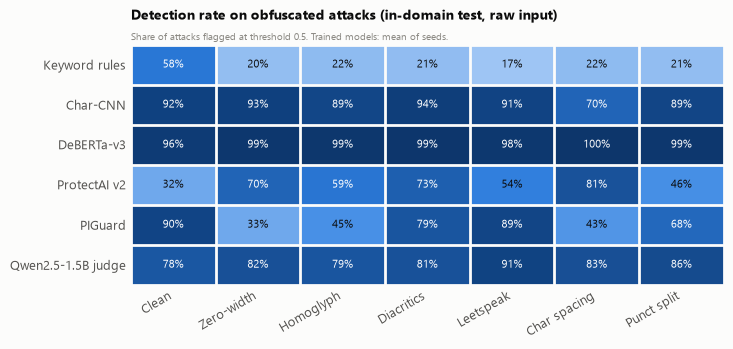

In [7]:
rob = analysis.robustness_matrix(metrics, "test_in", "tpr", "raw", MAIN)
rob.to_csv(TABLES / "t2_robustness_tpr_in_domain.csv")
plots.heatmap(rob, "Detection rate on obfuscated attacks (in-domain test, raw input)",
              "fig1_robustness_heatmap", row_labels=[LABEL[m] for m in rob.index],
              note="Share of attacks flagged at threshold 0.5. Trained models: mean of seeds.")
rob

In [8]:
drop = rob.sub(rob["clean"], axis=0).drop(columns="clean")
drop.to_csv(TABLES / "t2b_tpr_drop_vs_clean.csv")
drop

family,zero_width,homoglyph,diacritics,leetspeak,char_spacing,punct_split
model,,,,,,
rules,-0.380,-0.364,-0.369,-0.417,-0.364,-0.374
char_cnn,0.009,-0.029,0.021,-0.011,-0.219,-0.023
deberta,0.029,0.030,0.034,0.025,0.037,0.027
protectai,0.378,0.270,0.405,0.216,0.486,0.135
piguard,-0.572,-0.444,-0.107,-0.005,-0.471,-0.219
llm_judge,0.043,0.011,0.032,0.128,0.048,0.075


### Does obfuscation alone trigger an alarm?
False-positive rate on **obfuscated benign** prompts. A detector that flags these is reacting to
unusual characters, not to attack intent; that can look like robustness on attacks.

family,clean,zero_width,homoglyph,diacritics,leetspeak,char_spacing,punct_split
model,,,,,,,
rules,0.000,0.000,0.000,0.000,0.000,0.000,0.000
char_cnn,0.007,0.058,0.031,0.067,0.009,0.002,0.007
deberta,0.004,0.768,0.557,0.771,0.357,0.771,0.384
protectai,0.000,0.400,0.229,0.171,0.029,0.371,0.143
piguard,0.000,0.000,0.016,0.265,0.227,0.000,0.022
llm_judge,0.135,0.168,0.227,0.189,0.443,0.184,0.314


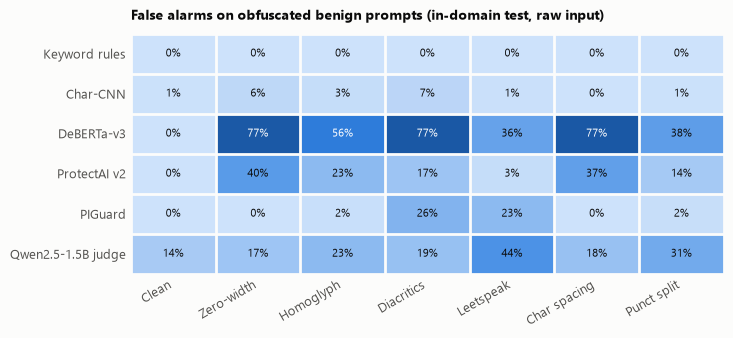

In [9]:
fpr = analysis.robustness_matrix(metrics, "test_in", "fpr", "raw", MAIN)
fpr.to_csv(TABLES / "t3_fpr_obfuscated_benign.csv")
plots.heatmap(fpr, "False alarms on obfuscated benign prompts (in-domain test, raw input)",
              "fig2_fpr_heatmap", row_labels=[LABEL[m] for m in fpr.index])
fpr

### Out-of-distribution jailbreaks (jackhhao)

family,clean,zero_width,homoglyph,diacritics,leetspeak,char_spacing,punct_split
model,,,,,,,
rules,0.645,0.355,0.380,0.430,0.365,0.435,0.420
char_cnn,0.780,0.828,0.785,0.870,0.772,0.453,0.700
deberta,0.962,1.000,1.000,1.000,0.995,1.000,0.997
piguard,0.955,0.080,0.955,0.990,0.995,0.690,0.970
llm_judge,0.870,0.905,0.895,0.915,0.955,0.910,0.915


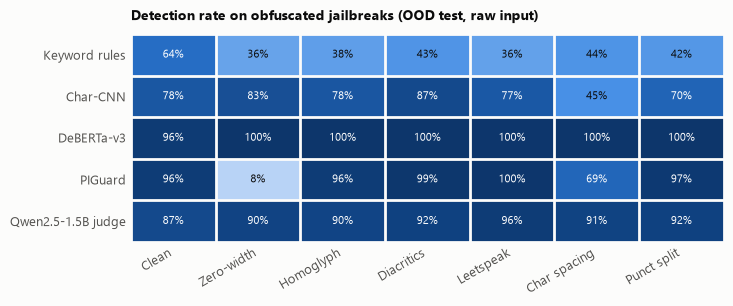

In [10]:
rob_ood = analysis.robustness_matrix(metrics, "test_ood", "tpr", "raw",
                                     [m for m in MAIN if m not in config.SEEN_BY or "jackhhao" not in config.SEEN_BY[m]])
rob_ood.to_csv(TABLES / "t4_robustness_tpr_ood.csv")
plots.heatmap(rob_ood, "Detection rate on obfuscated jailbreaks (OOD test, raw input)", "fig3_robustness_ood",
              row_labels=[LABEL[m] for m in rob_ood.index])
rob_ood

### Why sub-word models break: tokenisation damage
Sub-word tokens per whitespace word on the in-domain test set, for DeBERTa-v3's tokeniser.

In [11]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(config.model_id("deberta"))
td = analysis.tokenisation_damage(tok, bundle)
td_norm = analysis.tokenisation_damage(tok, bundle, text_col="text_norm").add_suffix("_after_norm")
td = td.join(td_norm)
td.to_csv(TABLES / "t5_tokenisation_damage.csv")
td

,tokens_per_word,unk_share,tokens_per_word_after_norm,unk_share_after_norm
family,,,,
clean,1.194,0.000,1.190,0.000
zero_width,2.542,0.243,1.190,0.000
homoglyph,2.423,0.028,1.283,0.000
diacritics,2.782,0.030,1.190,0.000
leetspeak,2.326,0.000,1.278,0.000
char_spacing,1.066,0.000,1.467,0.000
punct_split,2.496,0.000,1.190,0.000


In [12]:
from pi_hardening.perturb import perturb
word = "Please ignore the attached report"
for fam in ["clean"] + config.FAMILIES:
    t = perturb(word, fam, 1.0, seed=3)
    print(f"{fam:13s} {analysis.show_tokens(tok, t)}")

clean         ['▁Please', '▁ignore', '▁the', '▁attached', '▁report']
zero_width    ['▁P', '[UNK]', 'l', '[UNK]', 'ease', '▁i', 'gno', '[UNK]', 'r', '[UNK]', 'e', '▁th', '[UNK]', 'e', '▁a', '[UNK]', 'tta', 'che', '[UNK]', 'd', '▁re', '[UNK]', 'po', '[UNK]', 'rt']
homoglyph     ['▁P', 'ӏ', 'e', 'ɑ', 's', 'е', '▁і', 'ɡ', 'no', 'г', 'e', '▁t', 'һ', 'e', '▁ɑ', 'tta', 'ch', '[UNK]', 'ԁ', '▁', 'ге', 'port']
diacritics    ['▁P', '̈', 'l', '̀', 'ea', 's', 'ẽ', '▁ï', 'gn', 'ör', 'ê', '▁th', 'è', '▁', 'ätt', '̃', 'ach', '̀', 'ë', 'd', '▁', 'ŕ', 'ep', 'õ', 'r', '̂', 't']
leetspeak     ['▁Pl', '3', 'a', '53', '▁19', 'nor', '3', '▁7', 'h', '3', '▁47', 't', '4', 'ch', '3', 'd', '▁r', '3', 'por', '7']
char_spacing  ['▁P', '▁l', '▁e', '▁a', '▁s', '▁e', '▁i', '▁g', '▁n', '▁o', '▁r', '▁e', '▁t', '▁h', '▁e', '▁a', '▁t', '▁t', '▁a', '▁c', '▁h', '▁e', '▁d', '▁r', '▁e', '▁p', '▁o', '▁r', '▁t']
punct_split   ['▁P', '*', 'l', '*', 'ease', '▁ig', '*', 'no', '*', 're', '▁th', '.', 'e', '▁at', 'ta', '.', 'c', '.'

## RQ2 · Hardening DeBERTa: normaliser, augmentation, both

In [13]:
variants = {"Normaliser": ("deberta", "norm"), "Augmentation": ("deberta_aug", "raw"),
            "Both": ("deberta_aug", "norm")}
rec = analysis.recovery_table(metrics, "test_in", ("deberta", "raw"), variants).set_index("family")
rec.to_csv(TABLES / "t6_deberta_hardening_recovery.csv")
rec

,base_clean,base_obfuscated,loss,Normaliser_tpr,Normaliser_recovery,Augmentation_tpr,Augmentation_recovery,Both_tpr,Both_recovery
family,,,,,,,,,
zero_width,0.959,0.988,-0.029,0.959,NaN,0.911,NaN,0.943,NaN
homoglyph,0.959,0.989,-0.030,0.963,NaN,0.918,NaN,0.939,NaN
diacritics,0.959,0.993,-0.034,0.959,NaN,0.934,NaN,0.943,NaN
leetspeak,0.959,0.984,-0.025,0.970,NaN,0.923,NaN,0.947,NaN
char_spacing,0.959,0.996,-0.037,0.973,NaN,0.939,NaN,0.950,NaN
punct_split,0.959,0.986,-0.027,0.959,NaN,0.936,NaN,0.943,NaN


,No hardening,Normaliser,Augmentation,Both
family,,,,
clean,0.959,0.959,0.943,0.943
zero_width,0.988,0.959,0.911,0.943
homoglyph,0.989,0.963,0.918,0.939
diacritics,0.993,0.959,0.934,0.943
leetspeak,0.984,0.970,0.923,0.947
char_spacing,0.996,0.973,0.939,0.950
punct_split,0.986,0.959,0.936,0.943


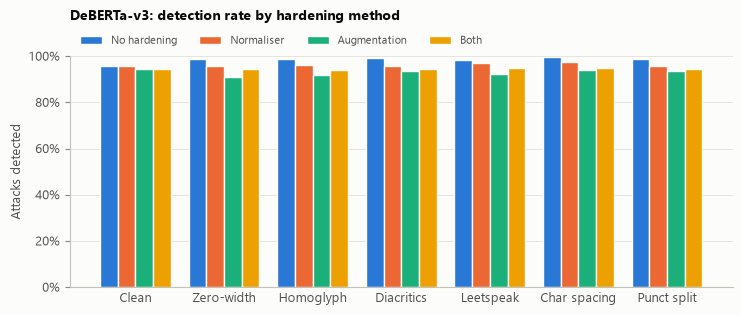

In [14]:
cols = {"No hardening": ("deberta", "raw"), **variants}
tab = pd.DataFrame({lab: analysis.robustness_matrix(metrics, "test_in", "tpr", c, [m]).loc[m]
                    for lab, (m, c) in cols.items()})
tab.to_csv(TABLES / "t7_deberta_variants_tpr.csv")
plots.grouped_bars(tab, ["clean"] + config.FAMILIES, {k: k for k in cols}, "DeBERTa-v3: detection rate by hardening method",
                   "fig4_deberta_hardening", "Attacks detected")
tab

### Paired bootstrap: is the improvement over plain DeBERTa reliable?
Difference in detection rate on the same attack samples, 95 % CI (2,000 resamples).

In [15]:
rows = []
for fam in config.FAMILIES:
    for lab, (m, c) in variants.items():
        d, lo, hi, n = evaluate.paired_tpr_diff(preds, (m, c), ("deberta", "raw"), "test_in", fam)
        rows.append({"family": fam, "variant": lab, "diff": d, "ci_low": lo, "ci_high": hi, "n_attacks": n})
ci = pd.DataFrame(rows)
ci.to_csv(TABLES / "t8_paired_bootstrap_deberta.csv", index=False)
ci.pivot(index="family", columns="variant", values="diff")

variant,Augmentation,Both,Normaliser
family,,,
char_spacing,-0.053,-0.043,-0.027
diacritics,-0.048,-0.059,-0.032
homoglyph,-0.059,-0.053,-0.027
leetspeak,-0.032,-0.048,-0.016
punct_split,-0.053,-0.059,-0.032
zero_width,-0.064,-0.059,-0.032


### The same methods on the Char-CNN

In [16]:
cnn_cols = {"Char-CNN": ("char_cnn", "raw"), "+ normaliser": ("char_cnn", "norm"),
            "+ augmentation": ("char_cnn_aug", "raw"), "+ both": ("char_cnn_aug", "norm")}
cnn = pd.DataFrame({lab: analysis.robustness_matrix(metrics, "test_in", "tpr", c, [m]).loc[m]
                    for lab, (m, c) in cnn_cols.items() if m in available})
cnn.to_csv(TABLES / "t9_charcnn_variants_tpr.csv")
cnn

,Char-CNN,+ normaliser,+ augmentation,+ both
family,,,,
clean,0.916,0.916,0.900,0.900
zero_width,0.925,0.916,0.897,0.900
homoglyph,0.888,0.918,0.893,0.900
diacritics,0.938,0.916,0.902,0.900
leetspeak,0.906,0.914,0.897,0.900
char_spacing,0.697,0.916,0.872,0.902
punct_split,0.893,0.916,0.904,0.900


### Normalisation in front of detectors we cannot retrain

In [17]:
fixed = [m for m in ["rules", "protectai", "piguard", "llm_judge"] if m in available]
fx = pd.concat({LABEL[m]: pd.DataFrame({"raw": analysis.robustness_matrix(metrics, "test_in", "tpr", "raw", [m]).loc[m],
                                        "normalised": analysis.robustness_matrix(metrics, "test_in", "tpr", "norm", [m]).loc[m]})
                for m in fixed}, axis=1)
fx.to_csv(TABLES / "t10_normaliser_on_fixed_detectors.csv")
fx

Keyword rules            ProtectAI v2            PIGuard  \
                       raw normalised          raw normalised     raw   
family                                                                  
clean                0.583      0.583        0.324      0.324   0.898   
zero_width           0.203      0.583        0.703      0.324   0.326   
homoglyph            0.219      0.529        0.595      0.324   0.455   
diacritics           0.214      0.583        0.730      0.324   0.791   
leetspeak            0.166      0.567        0.541      0.324   0.893   
char_spacing         0.219      0.406        0.811      0.405   0.428   
punct_split          0.209      0.583        0.459      0.324   0.679   

                        Qwen2.5-1.5B judge             
             normalised                raw normalised  
family                                                 
clean             0.898              0.781      0.770  
zero_width        0.898              0.824      0.770  
homoglyph         0.866              0.791      0.765  
diacritics        0.898              0.813      0.770  
leetspeak         0.893              0.909      0.813  
char_spacing      0.861              0.829      0.791  
punct_split       0.898              0.856      0.770

### Leave-one-family-out: does augmentation transfer to an unseen obfuscation? (seed 42)

,No augmentation,Augmented without this family,Augmented with all families
family,,,
zero_width,0.989,0.813,0.936
homoglyph,0.995,0.930,0.930
diacritics,0.995,0.936,0.947
leetspeak,0.989,0.930,0.952
char_spacing,1.000,0.957,0.963
punct_split,0.989,0.925,0.957


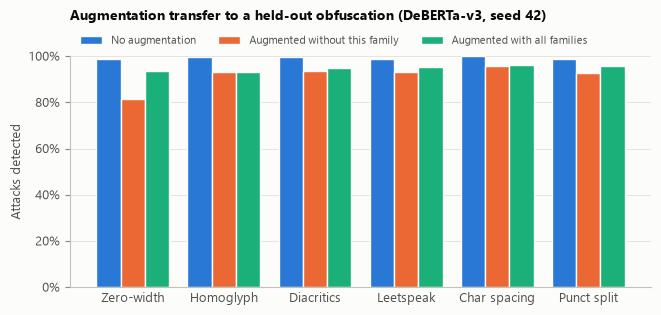

In [18]:
m42 = evaluate.metrics_table(preds[preds.seed.isin([42, 0])])
def tpr(model, fam, cond="raw"):
    r = m42.query("model == @model and family == @fam and condition == @cond and eval_set == 'test_in'")
    return float(r.tpr.iloc[0]) if len(r) else np.nan
lofo = pd.DataFrame([{"family": f, "No augmentation": tpr("deberta", f),
                      "Augmented without this family": tpr(f"deberta_aug_no_{f}", f),
                      "Augmented with all families": tpr("deberta_aug", f)} for f in config.FAMILIES]).set_index("family")
lofo.to_csv(TABLES / "t11_leave_one_family_out.csv")
plots.grouped_bars(lofo, config.FAMILIES, {k: k for k in lofo.columns},
                   "Augmentation transfer to a held-out obfuscation (DeBERTa-v3, seed 42)",
                   "fig5_leave_one_family_out", "Attacks detected")
lofo

## RQ3 · Cost of hardening: over-defence on NotInject

,label,fpr,fpr_sd
391,Keyword rules,0.035,NaN
376,Keyword rules + normaliser,0.035,NaN
315,Qwen2.5-1.5B judge,0.080,NaN
300,Qwen2.5-1.5B judge + normaliser,0.083,NaN
345,PIGuard,0.115,NaN
330,PIGuard + normaliser,0.124,NaN
90,DeBERTa-v3 + aug + normaliser,0.298,0.026
105,DeBERTa-v3 + aug,0.306,0.027
60,DeBERTa-v3 + normaliser,0.361,0.071
75,DeBERTa-v3,0.367,0.071


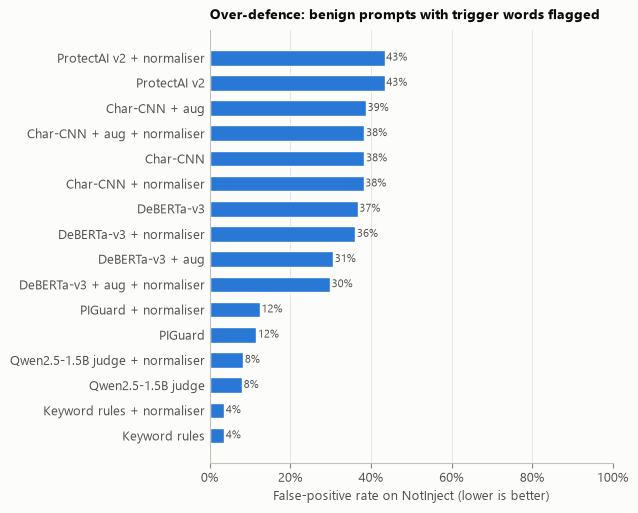

In [19]:
ni = metrics[(metrics.eval_set == "notinject") & metrics.model.isin(list(LABEL))].copy()
ni["label"] = ni.model.map(LABEL) + np.where(ni.condition == "norm", " + normaliser", "")
ni = ni.sort_values("fpr")
ni[["label", "fpr", "fpr_sd", "seeds"]].to_csv(TABLES / "t12_notinject_fpr.csv", index=False)
plots.hbar(ni["label"].tolist()[::-1], ni["fpr"].tolist()[::-1], "Over-defence: benign prompts with trigger words flagged",
           "fig6_notinject_fpr", "False-positive rate on NotInject (lower is better)")
ni[["label", "fpr", "fpr_sd"]]

In [20]:
by_trig = (preds.query("eval_set == 'notinject'")
           .assign(flag=lambda d: d.score >= 0.5)
           .groupby(["model", "condition", "n_triggers"])["flag"].mean().unstack())
by_trig.to_csv(TABLES / "t13_notinject_by_trigger_count.csv")
by_trig

n_triggers                             1.000  2.000  3.000
model                       condition                     
char_cnn                    norm       0.289  0.392  0.463
                            raw        0.292  0.395  0.463
char_cnn_aug                norm       0.286  0.404  0.460
                            raw        0.292  0.410  0.460
deberta                     norm       0.239  0.369  0.475
                            raw        0.245  0.378  0.478
deberta_aug                 norm       0.218  0.298  0.378
                            raw        0.215  0.319  0.383
deberta_aug_no_char_spacing norm       0.257  0.301  0.451
                            raw        0.257  0.354  0.451
deberta_aug_no_diacritics   norm       0.345  0.425  0.496
                            raw        0.345  0.442  0.496
deberta_aug_no_homoglyph    norm       0.239  0.354  0.434
                            raw        0.248  0.389  0.434
deberta_aug_no_leetspeak    norm       0.434  0.442  0.584
                            raw        0.434  0.451  0.593
deberta_aug_no_punct_split  norm       0.274  0.398  0.504
                            raw        0.274  0.398  0.513
deberta_aug_no_zero_width   norm       0.283  0.381  0.434
                            raw        0.292  0.381  0.451
llm_judge                   norm       0.044  0.035  0.168
                            raw        0.035  0.035  0.168
piguard                     norm       0.062  0.115  0.195
                            raw        0.053  0.106  0.186
protectai                   norm       0.239  0.522  0.540
                            raw        0.221  0.531  0.549
rules                       norm       0.018  0.035  0.053
                            raw        0.018  0.035  0.053

## RQ3 · Latency (batch size 1)

,label,device,median_ms,p95_ms
0,Keyword rules,cuda,0.018,0.073
1,Keyword rules + normaliser,cuda,0.059,0.228
4,Char-CNN + aug,cuda,0.931,1.007
2,Char-CNN,cuda,0.942,1.615
3,Char-CNN + normaliser,cuda,0.974,1.204
5,Char-CNN + aug + normaliser,cuda,1.004,1.289
13,PIGuard + normaliser,cuda,26.933,31.654
11,ProtectAI v2 + normaliser,cuda,27.735,36.011
8,DeBERTa-v3 + aug,cuda,28.108,38.112
10,ProtectAI v2,cuda,28.140,35.121


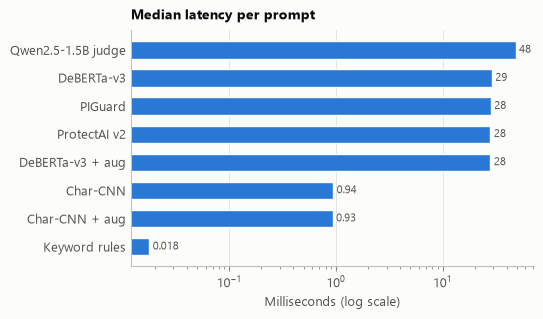

In [21]:
lat = pd.read_csv(config.RESULTS_DIR / "latency.csv")
lat["label"] = lat.model.map(LABEL).fillna(lat.model) + np.where(lat.with_normaliser, " + normaliser", "")
lat = lat.sort_values("median_ms")
lat.to_csv(TABLES / "t14_latency.csv", index=False)
plain = lat[~lat.with_normaliser]
plots.hbar(plain["label"].tolist()[::-1], plain["median_ms"].tolist()[::-1], "Median latency per prompt",
           "fig7_latency", "Milliseconds (log scale)", percent=False, log=True)
lat[["label", "device", "median_ms", "p95_ms"]]

## Error analysis
Attacks the best hardened configuration still misses, per family (counts), and a few examples.

In [22]:
best = ("deberta_aug", "norm")
best_model, best_cond = best
missed = (preds.query("model == @best_model and condition == @best_cond and eval_set == 'test_in' and label == 1")
          .groupby(["family", "uid"])["score"].mean().lt(0.5).groupby("family").agg(["sum", "size"]))
missed.columns = ["missed", "attacks"]
missed.to_csv(TABLES / "t15_missed_by_best.csv")
missed

,missed,attacks
family,,
char_spacing,8,187
clean,13,187
diacritics,13,187
homoglyph,12,187
leetspeak,11,187
punct_split,13,187
zero_width,13,187


In [23]:
ex = analysis.error_examples(preds, bundle, *best, "test_in", "char_spacing", "missed", n=5)
ex.assign(clean_text=ex.clean_text.str.slice(0, 120))[["uid", "score", "clean_text"]]

[Output removed in the public copy: it lists original dataset prompts. Run the notebook locally to see it.]


## Key numbers for the report

In [24]:
def g(model, cond, fam, metric="tpr", es="test_in"):
    r = metrics.query("model == @model and condition == @cond and family == @fam and eval_set == @es")
    return float(r[metric].iloc[0]) if len(r) else float("nan")
fams = config.FAMILIES
print(f"DeBERTa clean TPR {g('deberta','raw','clean'):.1%}; mean over families {np.mean([g('deberta','raw',f) for f in fams]):.1%}")
print(f"+ normaliser mean {np.mean([g('deberta','norm',f) for f in fams]):.1%}; + aug mean {np.mean([g('deberta_aug','raw',f) for f in fams]):.1%}; "
      f"both {np.mean([g('deberta_aug','norm',f) for f in fams]):.1%}")
print(f"NotInject FPR: DeBERTa {g('deberta','raw','clean','fpr','notinject'):.1%}, both {g('deberta_aug','norm','clean','fpr','notinject'):.1%}")

DeBERTa clean TPR 95.9%; mean over families 98.9%
+ normaliser mean 96.4%; + aug mean 92.7%; both 94.4%
NotInject FPR: DeBERTa 36.7%, both 29.8%
